<a href="https://colab.research.google.com/github/ngphuc-ict/vietnamese-hotel-review-phobert/blob/main/VietnameseHotelReviewPhoBERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# [CELL 1] SETUP THƯ VIỆN & KẾT NỐI DRIVE
!pip install -q transformers
!pip install -q pyvi

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# [CELL 2] IMPORT VÀ CẤU HÌNH THAM SỐ
import time
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer
from pyvi import ViTokenizer
import matplotlib.pyplot as plt

# Cấu hình thiết bị
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang chạy trên thiết bị: {device}")

# Đường dẫn đến các file dữ liệu
BASE_DIR = "/content/drive/MyDrive/CMC-AI/vi-sentiment-analysis/VLSP-2018/"
TRAIN_FILE = BASE_DIR + "1-VLSP2018-SA-Hotel-train.csv"
DEV_FILE   = BASE_DIR + "2-VLSP2018-SA-Hotel-dev.csv"
TEST_FILE  = BASE_DIR + "3-VLSP2018-SA-Hotel-test.csv"

# Hyperparameters cho PhoBERT
MAX_LEN = 256        # Đảm bảo bao phủ >99% chiều dài câu
BATCH_SIZE = 32      # Giảm xuống 16 để tránh tràn VRAM GPU
LEARNING_RATE = 2e-5 # Learning rate cực nhỏ cho Fine-tuning PhoBERT
EPOCHS = 50

Đang chạy trên thiết bị: cuda


In [ ]:
# [CELL 3] PREPROCESSING & DATASET VỚI PHO-BERT
tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base", use_fast=False)

class PhoBertHotelDataset(Dataset):
    def __init__(self, csv_file, tokenizer, max_len):
        self.df = pd.read_csv(csv_file)
        self.tokenizer = tokenizer
        self.max_len = max_len

        # Tự động nhận diện 34 cột aspects
        self.aspect_cols = [c for c in self.df.columns if c.lower() != 'review']
        self.num_aspects = len(self.aspect_cols)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        text = str(self.df.iloc[idx]['Review'])

        # BẮT BUỘC: Tách từ tiếng Việt cho PhoBERT (VD: "nhân viên" -> "nhân_viên")
        segmented_text = ViTokenizer.tokenize(text)

        labels = self.df.iloc[idx][self.aspect_cols].values.astype(int)

        encoding = self.tokenizer(
            segmented_text,
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(labels, dtype=torch.long)
        }

# Khởi tạo DataLoader
train_dataset = PhoBertHotelDataset(TRAIN_FILE, tokenizer, MAX_LEN)
dev_dataset = PhoBertHotelDataset(DEV_FILE, tokenizer, MAX_LEN)
test_dataset = PhoBertHotelDataset(TEST_FILE, tokenizer, MAX_LEN)

NUM_ASPECTS = train_dataset.num_aspects

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Số lượng khía cạnh (Aspects): {NUM_ASPECTS}")
print("Đã nạp xong Tokenizer và DataLoader!")

Số lượng khía cạnh (Aspects): 34
Đã nạp xong Tokenizer và DataLoader!


In [ ]:
# [CELL 4] MÔ HÌNH PHO-BERT ABSA
class PhoBertABSA(nn.Module):
    def __init__(self, num_aspects, num_classes=4, dropout_rate=0.3):
        super().__init__()
        self.num_aspects = num_aspects
        self.num_classes = num_classes

        # Tải mô hình PhoBERT-base
        self.phobert = AutoModel.from_pretrained("vinai/phobert-base")

        self.dropout = nn.Dropout(dropout_rate)
        # Kích thước hidden state của PhoBERT-base là 768
        self.classifier = nn.Linear(768, num_aspects * num_classes)

    def forward(self, input_ids, attention_mask):
        # Trích xuất đặc trưng từ PhoBERT
        outputs = self.phobert(input_ids=input_ids, attention_mask=attention_mask)

        # Lấy vector của token [CLS] (vị trí 0) làm vector đại diện cho cả câu
        cls_output = outputs.last_hidden_state[:, 0, :]

        cls_output = self.dropout(cls_output)
        logits = self.classifier(cls_output)

        # Định hình lại output thành (Batch, Num_Aspects, Num_Classes)
        return logits.view(-1, self.num_aspects, self.num_classes)

model = PhoBertABSA(num_aspects=NUM_ASPECTS).to(device)

print(model)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


PhoBertABSA(
  (phobert): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(64001, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(258, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNo

In [ ]:
# [CELL 5] HÀM MẤT MÁT VÀ ĐÁNH GIÁ
# Phạt nhẹ class 0 để cân bằng dữ liệu
class_weights = torch.tensor([1.0, 2.0, 2.0, 2.0]).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-2)

def compute_loss(logits, targets):
    return criterion(logits.view(-1, 4), targets.view(-1))

def evaluate_tuples(logits, targets):
    preds = torch.argmax(logits, dim=-1).cpu().numpy()
    targets = targets.cpu().numpy()
    tp, fp, fn = 0, 0, 0
    for i in range(len(preds)):
        # Loại bỏ nhãn 0 (None)
        pred_set = set([(j, preds[i][j]) for j in range(NUM_ASPECTS) if preds[i][j] > 0])
        true_set = set([(j, targets[i][j]) for j in range(NUM_ASPECTS) if targets[i][j] > 0])

        tp += len(pred_set & true_set)
        fp += len(pred_set - true_set)
        fn += len(true_set - pred_set)
    return tp, fp, fn

In [ ]:
# [CELL 6] FINE-TUNING LOOP
best_f1 = 0.0
patience = 3
patience_counter = 0
history_train_loss = []

print("Bắt đầu Fine-tuning PhoBERT...")
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)
        loss = compute_loss(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)
    history_train_loss.append(avg_train_loss)

    # Đánh giá tập Dev
    model.eval()
    v_tp, v_fp, v_fn = 0, 0, 0
    with torch.no_grad():
        for batch in dev_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            logits = model(input_ids, attention_mask)
            tp, fp, fn = evaluate_tuples(logits, labels)
            v_tp += tp
            v_fp += fp
            v_fn += fn

    prec = v_tp / (v_tp + v_fp) if (v_tp + v_fp) > 0 else 0
    rec = v_tp / (v_tp + v_fn) if (v_tp + v_fn) > 0 else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Dev F1: {f1:.4f}")

    # Lưu Model tốt nhất
    if f1 > best_f1:
        best_f1 = f1
        patience_counter = 0
        torch.save(model.state_dict(), '/content/best_phobert_hotel.pth')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping kích hoạt tại epoch {epoch+1}!")
            break

Bắt đầu Fine-tuning PhoBERT...
Epoch 1/50 | Train Loss: 0.8904 | Dev F1: 0.3188
Epoch 2/50 | Train Loss: 0.6837 | Dev F1: 0.3281
Epoch 3/50 | Train Loss: 0.6103 | Dev F1: 0.3690
Epoch 4/50 | Train Loss: 0.5543 | Dev F1: 0.4410
Epoch 5/50 | Train Loss: 0.5125 | Dev F1: 0.4906
Epoch 6/50 | Train Loss: 0.4748 | Dev F1: 0.5308
Epoch 7/50 | Train Loss: 0.4431 | Dev F1: 0.5571
Epoch 8/50 | Train Loss: 0.4145 | Dev F1: 0.5870
Epoch 9/50 | Train Loss: 0.3905 | Dev F1: 0.5997
Epoch 10/50 | Train Loss: 0.3675 | Dev F1: 0.6118
Epoch 11/50 | Train Loss: 0.3479 | Dev F1: 0.6268
Epoch 12/50 | Train Loss: 0.3289 | Dev F1: 0.6478
Epoch 13/50 | Train Loss: 0.3123 | Dev F1: 0.6535
Epoch 14/50 | Train Loss: 0.2960 | Dev F1: 0.6613
Epoch 15/50 | Train Loss: 0.2806 | Dev F1: 0.6705
Epoch 16/50 | Train Loss: 0.2675 | Dev F1: 0.6794
Epoch 17/50 | Train Loss: 0.2539 | Dev F1: 0.6800
Epoch 18/50 | Train Loss: 0.2397 | Dev F1: 0.6875
Epoch 19/50 | Train Loss: 0.2285 | Dev F1: 0.6925
Epoch 20/50 | Train Loss: 0.

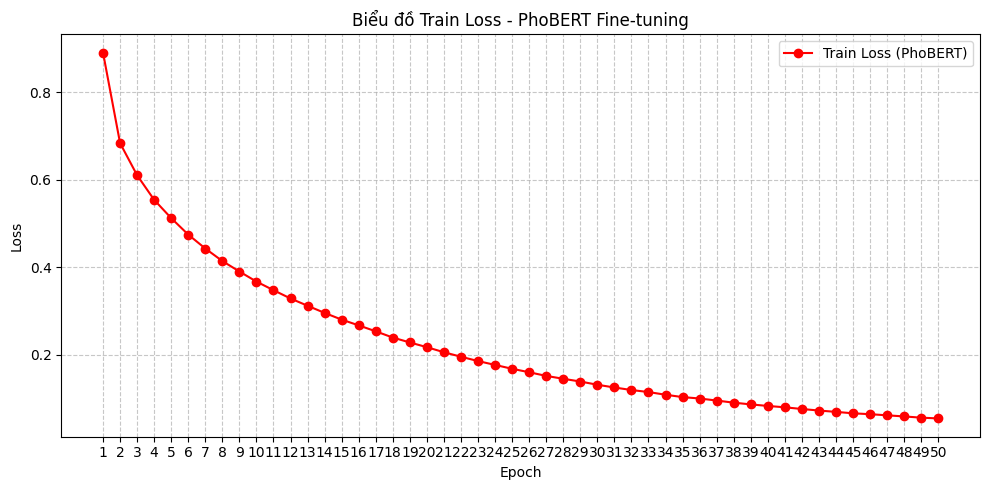

In [ ]:
# Vẽ biểu đồ
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(history_train_loss) + 1), history_train_loss, marker='o', color='r', label='Train Loss (PhoBERT)')
plt.title('Biểu đồ Train Loss - PhoBERT Fine-tuning')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(range(1, len(history_train_loss) + 1))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig('/content/phobert_loss_chart.png')
plt.show()

In [ ]:
# [CELL 7] KIỂM THỬ TRÊN TẬP TEST
model.load_state_dict(torch.load('/content/best_phobert_hotel.pth', weights_only=True))
model.eval()

t_tp, t_fp, t_fn = 0, 0, 0
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        logits = model(input_ids, attention_mask)
        tp, fp, fn = evaluate_tuples(logits, labels)
        t_tp += tp
        t_fp += fp
        t_fn += fn

t_prec = t_tp / (t_tp + t_fp) if (t_tp + t_fp) > 0 else 0
t_rec = t_tp / (t_tp + t_fn) if (t_tp + t_fn) > 0 else 0
t_f1 = 2 * t_prec * t_rec / (t_prec + t_rec) if (t_prec + t_rec) > 0 else 0

print("=========================================")
print("=== KẾT QUẢ ĐÁNH GIÁ PHO-BERT (TEST) ===")
print(f"Precision : {t_prec:.4f}")
print(f"Recall    : {t_rec:.4f}")
print(f"F1-Score  : {t_f1:.4f}")
print("=========================================")

=== KẾT QUẢ ĐÁNH GIÁ PHO-BERT (TEST) ===
Precision : 0.7926
Recall    : 0.7175
F1-Score  : 0.7532


In [ ]:
# [CELL 8] BENCHMARK ĐỘ TRỄ & FPS
sample = next(iter(test_loader))
s_ids = sample['input_ids'][:1].to(device)
s_mask = sample['attention_mask'][:1].to(device)

model.eval()

# Warm-up GPU/CPU
with torch.no_grad():
    for _ in range(10):
        _ = model(s_ids, s_mask)

latencies = []
num_samples = 50  # Lấy mẫu thời gian trên 50 lần suy luận

with torch.no_grad():
    for _ in range(num_samples):
        if device.type == 'cuda':
            start_event = torch.cuda.Event(enable_timing=True)
            end_event = torch.cuda.Event(enable_timing=True)

            start_event.record()
            _ = model(s_ids, s_mask)
            end_event.record()

            torch.cuda.synchronize()
            latencies.append(start_event.elapsed_time(end_event))
        else:
            t0 = time.perf_counter()
            _ = model(s_ids, s_mask)
            latencies.append((time.perf_counter() - t0) * 1000.0)

avg_lat = np.mean(latencies)
fps = 1000.0 / avg_lat if avg_lat > 0 else 0

print(f"=== BENCHMARK MÔ HÌNH ({num_samples} Samples) ===")
print(f"Thời gian suy luận (Latency) : {avg_lat:.2f} ms / sample")
print(f"Tốc độ xử lý (FPS)           : {fps:.2f} samples/second")
print("=========================================")

=== BENCHMARK MÔ HÌNH (50 Samples) ===
Thời gian suy luận (Latency) : 15.64 ms / sample
Tốc độ xử lý (FPS)           : 63.94 samples/second
